# SaaS Revenue Control Room

Aryan Kaushik | Personal analytics project

## 1. The question

I wanted to explain a change in recurring revenue without stopping at a dashboard total. Here I work from subscription records to monthly metrics, then check the figures against billing records.

- The data is entirely synthetic and generated with seed 89.
- There are 360 fictional accounts. Reporting runs from January 2025 through September 2026, with December 2024 as the opening baseline.
- MRR is a subscription run rate. It is different from invoices, cash and recognized revenue.

The dashboard opens from `dist/index.html`. The same results are available here without using the interface.


In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from generate_data import make_data
from analysis import run_sql
from analysis import monthly_summary
from analysis import cohort_summary
from analysis import data_checks

ROOT = Path.cwd()
pd.set_option('display.max_columns', 15)
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'axes.titleweight': 'bold'})

## 2. Read the source records

Here I recreate the same data, then look at the customer and event records. The customer table gives each account a fixed region and acquisition channel. Events describe the subscription state from an effective date onward.


In [2]:
make_data()
customers = pd.read_csv(ROOT / 'data/customers.csv')
events = pd.read_csv(ROOT / 'data/subscription_events_raw.csv')
invoices_raw = pd.read_csv(ROOT / 'data/invoices_raw.csv')

print(customers.head(8).to_string(index=False))
print('\nSource rows')
print(pd.Series({'customers': len(customers), 'events': len(events), 'invoices': len(invoices_raw)}).to_string())

customer_id             company        region channel currency signup_date
      C0001        Maple Annual        Canada Organic      CAD  2024-12-01
      C0002         Harbour USD United States Organic      USD  2024-12-01
      C0003      Free Workspace        Canada Organic      CAD  2024-12-01
      C0004    Midmonth Upgrade        Canada Organic      CAD  2024-12-01
      C0005 Annual New Business        Canada Organic      CAD  2026-02-01
      C0006   Returning Account        Canada Organic      CAD  2024-12-01
      C0007   Cancelled Account        Canada Organic      CAD  2024-12-01
      C0008    Past Due Account        Canada Organic      CAD  2024-12-01

Source rows
customers     360
events       1184
invoices     3672


## 3. Check the grain before joining

Some records are deliberately delivered twice. Counting both copies would inflate the results. I check those duplicates first. The SQL keeps the latest delivery of each event and removes identical repeated invoices before joining payment and credit totals.


In [3]:
duplicate_checks = pd.DataFrame({
    'source': ['Subscription events', 'Invoice records'],
    'repeated_identifiers': [events.duplicated('event_id').sum(), invoices_raw.duplicated('invoice_id').sum()]
})
print(duplicate_checks.to_string(index=False))

             source  repeated_identifiers
Subscription events                     3
    Invoice records                     2


## 4. Reconstruct the month end subscription state

The SQL ranks events by their effective date within each customer and reporting month. It uses the most recent event available by month end, normalizes annual prices and joins that month's FX rate.

The next query compares each account with its previous month. It labels new business, reactivation, expansion, contraction, churn and currency movement before adding them together.


In [4]:
metrics, invoice_ledger = run_sql()
monthly = monthly_summary(metrics)
latest = metrics[metrics['month'] == '2026-09']

example_accounts = latest[latest['customer_id'].isin(['C0001', 'C0002', 'C0004', 'C0006', 'C0007', 'C0008'])]
print(example_accounts[['company', 'billing_interval', 'status', 'local_mrr', 'opening_mrr', 'closing_mrr', 'reactivation_mrr', 'churn_mrr', 'fx_mrr']].round(2).to_string(index=False))

          company billing_interval    status  local_mrr  opening_mrr  closing_mrr  reactivation_mrr  churn_mrr  fx_mrr
     Maple Annual             year    active      100.0       100.00       100.00               0.0        0.0    0.00
      Harbour USD            month    active      100.0       135.94       136.64               0.0        0.0    0.71
 Midmonth Upgrade            month    active      200.0       100.00       200.00               0.0        0.0    0.00
Returning Account            month    active      100.0         0.00       100.00             100.0        0.0    0.00
Cancelled Account            month cancelled        0.0       100.00         0.00               0.0     -100.0    0.00
 Past Due Account            month  past_due      100.0       100.00       100.00               0.0        0.0    0.00


The annual account contributes its monthly equivalent. A past-due subscription still contributes MRR under the stated definition. A returning account is reactivation rather than first-time acquisition. The USD account can change in reported CAD even when its local contract does not change.

## 5. Look at the revenue trend

Here I plot closing MRR over the reporting period. This is the reported CAD value, so currency can affect the line. Retention is reviewed separately at constant currency.


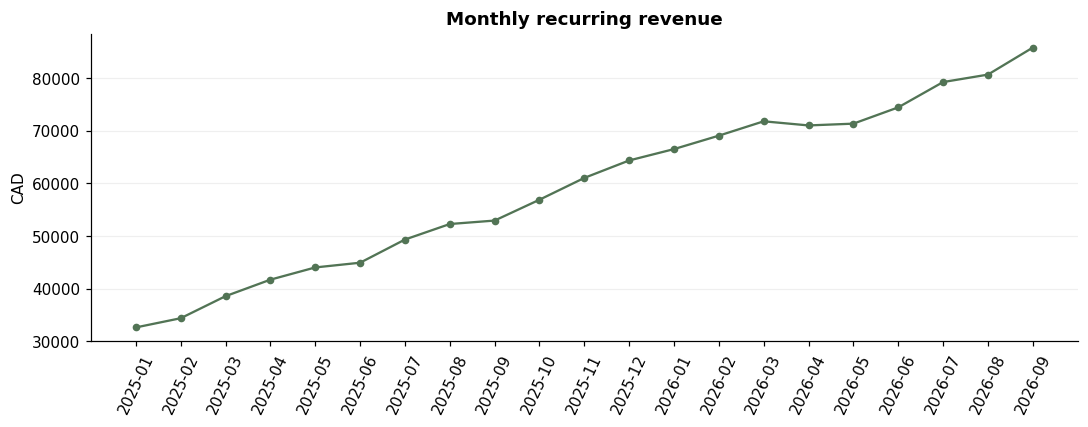

In [5]:
reporting = monthly[monthly['month'] > '2024-12']
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(reporting['month'], reporting['closing_mrr'], color='#527455', marker='o', markersize=4)
ax.set_title('Monthly recurring revenue')
ax.set_ylabel('CAD')
ax.tick_params(axis='x', rotation=65)
ax.grid(axis='y', alpha=.2)
fig.tight_layout()
fig.savefig(ROOT / 'outputs/mrr_trend.png', dpi=140)

## 6. Explain the latest movement

I check the six signed movements against the opening and closing balance. The same identity should hold for one customer, a channel, a region and the entire business.


month                     2026-09
opening_mrr          80696.170685
closing_mrr           85826.85005
nrr                      0.967961
grr                      0.947677
bridge_difference            -0.0


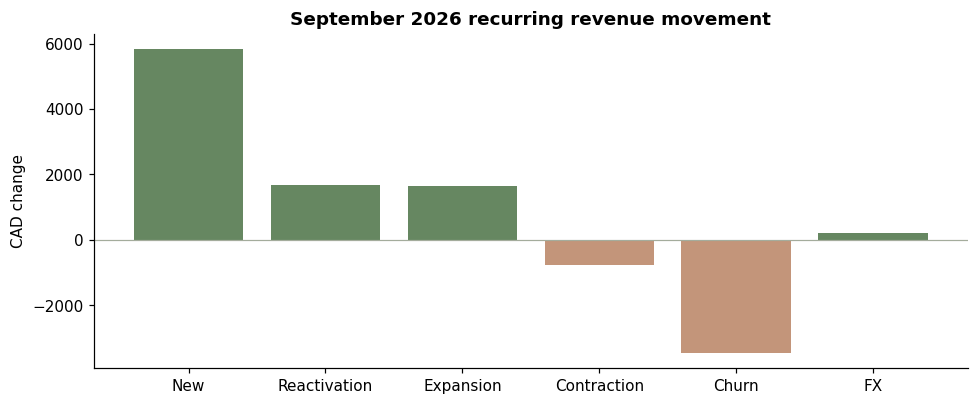

In [6]:
last = monthly.iloc[-1]
movement_names = ['New', 'Reactivation', 'Expansion', 'Contraction', 'Churn', 'FX']
movement_columns = ['new_mrr', 'reactivation_mrr', 'expansion_mrr', 'contraction_mrr', 'churn_mrr', 'fx_mrr']
movement_values = last[movement_columns].astype(float)

print(last[['month', 'opening_mrr', 'closing_mrr', 'nrr', 'grr', 'bridge_difference']].to_string())
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.bar(movement_names, movement_values, color=['#668761' if value >= 0 else '#c3957a' for value in movement_values])
ax.axhline(0, color='#a4ac9c', linewidth=.8)
ax.set_title('September 2026 recurring revenue movement')
ax.set_ylabel('CAD change')
fig.tight_layout()
fig.savefig(ROOT / 'outputs/mrr_movements.png', dpi=140)

## 7. Separate growth from retention

NRR follows the customers who were paying at the opening of the month. I use their opening FX rates to remove currency movement. GRR uses the same cohort but caps each account at its opening amount, so expansion cannot offset customer losses.

I also compare channels and inspect cohort retention. These are descriptive checks. The generator deliberately changes later paid-search churn probabilities, so a difference here is not evidence about real campaigns.


In [7]:
channel_results = []
for channel, rows in latest.groupby('channel'):
    result = monthly_summary(rows).iloc[0]
    channel_results.append({'channel': channel, 'closing_mrr': result['closing_mrr'], 'NRR': result['nrr'], 'GRR': result['grr']})

print(pd.DataFrame(channel_results).round(4).to_string(index=False))
cohorts = cohort_summary(metrics)
print('\nRecent cohort observations')
print(cohorts[cohorts['month'] == '2026-09'].tail(6).round(3).to_string(index=False))

    channel  closing_mrr    NRR    GRR
    Organic   33268.3695 0.9766 0.9553
   Outbound    8452.6703 0.9563 0.9009
Paid search   27798.7946 0.9383 0.9320
    Partner   16307.0157 1.0079 0.9844

Recent cohort observations
 cohort   month  active  customers  logo_retention
2026-04 2026-09       6          8           0.750
2026-05 2026-09       8          8           1.000
2026-06 2026-09       9         11           0.818
2026-07 2026-09      11         14           0.786
2026-08 2026-09       8          8           1.000
2026-09 2026-09      17         17           1.000


## 8. Compare recurring revenue with billing and cash

The midmonth example ends September at CAD 200 MRR. Its invoice is CAD 153.33 because the higher price applies to only 16 of September's 30 days.

For each invoice I compare net billed value with payments less refunds and the remaining balance. The selected month's invoice balance is not the same thing as total accounts receivable from all prior months. Recognized revenue is outside this model.


In [8]:
midmonth = invoice_ledger[(invoice_ledger['customer_id'] == 'C0004') & (invoice_ledger['month'] == '2026-09')]
print(midmonth[['invoice_id', 'company', 'gross_minor', 'net_billed_cad', 'net_cash_cad', 'outstanding_cad']].to_string(index=False))

bill_month = invoice_ledger[invoice_ledger['month'] == '2026-09']
print('\nSeptember invoice cohort, CAD')
print(bill_month[['net_billed_cad', 'net_cash_cad', 'outstanding_cad']].sum().round(2).to_string())

invoice_id          company  gross_minor  net_billed_cad  net_cash_cad  outstanding_cad
    I00043 Midmonth Upgrade        15333          153.33        153.33              0.0

September invoice cohort, CAD
net_billed_cad     83558.88
net_cash_cad       79587.48
outstanding_cad     3971.40


## 9. Review the data checks

These checks stay visible as a table. The separate automated tests cover the known accounts, segment reconciliation and the interface calculations, including empty selections.


In [9]:
checks = data_checks(metrics, invoice_ledger)
print(checks.to_string(index=False))

                                  check  passed
                 One customer per month    True
     Every customer movement reconciles    True
        Every monthly bridge reconciles    True
     Invoice cash and balance reconcile    True
   Outstanding balances are nonnegative    True
  Three repeated event deliveries found    True
      Two repeated invoice rows removed    True
Free accounts have no recurring revenue    True


## 10. What the result supports

In September, total MRR grows while the opening customer cohort loses some value at constant currency. I would check customer losses alongside acquisition before recommending more spend. I would then inspect account histories and compare billing and collection issues separately.

The current values and detailed interpretation are saved in `docs/findings.md`. `docs/walkthrough.md` explains the app controls and the calculation path. This project demonstrates analytical reasoning and delivery using generated records. It does not show a real company's commercial performance or a causal campaign effect.
